In [132]:
import matplotlib.pyplot as plt
from helpers import *
from preprocessing import *
from training import *
from postprocessing import *

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [128]:
data_path = "./data/dataset"

In [129]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path, sub_sample=False)
header = check_header(x_train, data_path)
x_train, x_test, header = drop_high_missing_features(x_train, x_test, header, threshold=0.9)

Header okay!


In [130]:
print(np.shape(x_train))
print(np.shape(x_test))

(328135, 222)
(109379, 222)


In [133]:
# build features on train, then apply the same encoding to test
X_train, X_test, feature_names = build_feature_matrix(x_train, x_test, header)

# add bias column
tx_train = add_bias(X_train)
tx_test = add_bias(X_test)

# sanity checks
print("Train:", tx_train.shape, "| Test:", tx_test.shape)  # same number of columns
print("NaN in X?", np.isnan(tx_train).any(), np.isnan(tx_test).any())  # False, False
print("y values:", np.unique(y_train, return_counts=True))  # -1 / 1, about 9% of 1

Train: (328135, 550) | Test: (109379, 550)
NaN in X? False False
y values: (array([-1,  1]), array([299160,  28975]))


In [134]:
w0 = np.zeros(tx_train.shape[1])
print("Loss at w=0:", compute_loss(y_train, tx_train, w0), "| log(2) =", np.log(2))

Loss at w=0: 0.6931471805599453 | log(2) = 0.6931471805599453


In [135]:
# random w to avoid the trivial point w=0
rng = np.random.default_rng(0)
w = rng.normal(scale=0.01, size=tx_train.shape[1])
lambda_ = 0.1
eps = 1e-6

# loss including the ridge penalty (bias not penalized), to match compute_gradient
def full_loss(w):
    return compute_loss(y_train, tx_train, w) + lambda_ * np.sum(w[1:] ** 2)

grad = compute_gradient(y_train, tx_train, w, lambda_)
for i in [0, 1, 5, 10]:
    e = np.zeros_like(w)
    e[i] = eps
    num_grad = (full_loss(w + e) - full_loss(w - e)) / (2 * eps)
    print(f"coord {i:3d} | analytic: {grad[i]: .8f} | numerical: {num_grad: .8f}")

coord   0 | analytic:  0.39289364 | numerical:  0.39289364
coord   1 | analytic:  0.00623268 | numerical:  0.00623268
coord   5 | analytic:  0.01271037 | numerical:  0.01271037
coord  10 | analytic:  0.00713027 | numerical:  0.00713027


In [136]:
tx_tr, tx_val, y_tr, y_val = split_data(tx_train, y_train, ratio=0.8, seed=0)
print("Train part:", tx_tr.shape, "| Validation part:", tx_val.shape)
print("Positives in train part:", np.mean(y_tr == 1), "| in validation part:", np.mean(y_val == 1))

Train part: (262508, 550) | Validation part: (65627, 550)
Positives in train part: 0.08817255093178113 | in validation part: 0.08882015024304021


In [137]:
w_init = np.zeros(tx_tr.shape[1])

w, history = sgd_logistic(
    y_tr, tx_tr,
    lambda_= 0,
    initial_w=w_init,
    max_epochs=100,
    gamma=0.001,
    batch_size=32,
    tx_val=tx_val, y_val=y_val,
)

epoch   1/100 | train loss: 0.22918 | val loss: 0.23011
epoch   2/100 | train loss: 0.22611 | val loss: 0.22686
epoch   3/100 | train loss: 0.22460 | val loss: 0.22547
epoch   4/100 | train loss: 0.22376 | val loss: 0.22470
epoch   5/100 | train loss: 0.22325 | val loss: 0.22416
epoch   6/100 | train loss: 0.22282 | val loss: 0.22378
epoch   7/100 | train loss: 0.22245 | val loss: 0.22349
epoch   8/100 | train loss: 0.22221 | val loss: 0.22327
epoch   9/100 | train loss: 0.22206 | val loss: 0.22311
epoch  10/100 | train loss: 0.22189 | val loss: 0.22307
epoch  11/100 | train loss: 0.22179 | val loss: 0.22303
epoch  12/100 | train loss: 0.22163 | val loss: 0.22280
epoch  13/100 | train loss: 0.22152 | val loss: 0.22276
epoch  14/100 | train loss: 0.22157 | val loss: 0.22289
epoch  15/100 | train loss: 0.22153 | val loss: 0.22288
epoch  16/100 | train loss: 0.22131 | val loss: 0.22258
epoch  17/100 | train loss: 0.22125 | val loss: 0.22251
epoch  18/100 | train loss: 0.22119 | val loss: 

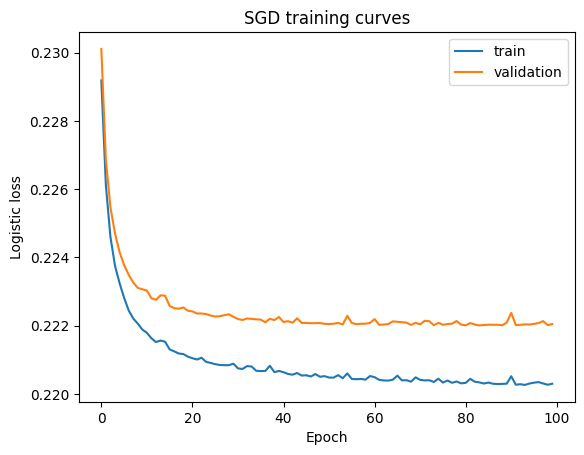

In [138]:
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Logistic loss")
plt.title("SGD training curves")
plt.legend()
plt.show()

In [139]:
# baseline: always predict -1 (not sick)
y_baseline = -np.ones_like(y_val)
print("Baseline (always -1):", compute_metrics(y_val, y_baseline))

# model with the default threshold 0.5
y_pred_05 = predict_labels(tx_val, w, threshold=0.5)
print("Model, threshold 0.5: ", compute_metrics(y_val, y_pred_05))

Baseline (always -1): {'accuracy': np.float64(0.9111798497569598), 'precision': 0.0, 'recall': np.float64(0.0), 'f1': 0.0}
Model, threshold 0.5:  {'accuracy': np.float64(0.9146540295914791), 'precision': np.float64(0.571969696969697), 'recall': np.float64(0.15542974781266083), 'f1': np.float64(0.24443545123431812)}


Best threshold: 0.20 | F1: 0.4312
Model, best threshold: {'accuracy': np.float64(0.8708915537812181), 'precision': np.float64(0.3541804544451798), 'recall': np.float64(0.5508663578658431), 'f1': np.float64(0.43115139308492784)}


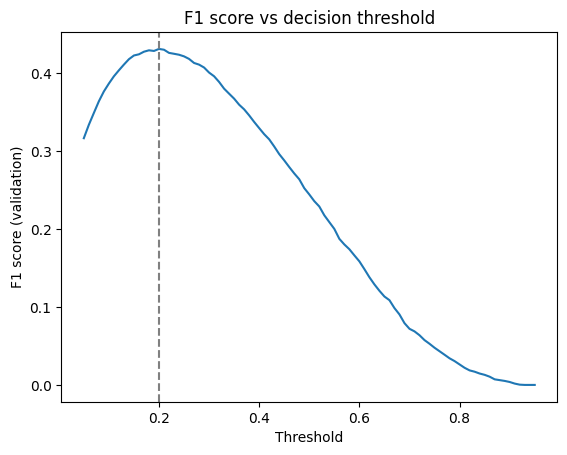

In [140]:
proba_val = predict_proba(tx_val, w)
thresholds = np.linspace(0.05, 0.95, 91)
best_t, best_f1, f1_scores = find_best_threshold(y_val, proba_val, thresholds)

print(f"Best threshold: {best_t:.2f} | F1: {best_f1:.4f}")
print("Model, best threshold:", compute_metrics(y_val, predict_labels(tx_val, w, best_t)))

plt.plot(thresholds, f1_scores)
plt.axvline(best_t, linestyle="--", color="gray")
plt.xlabel("Threshold")
plt.ylabel("F1 score (validation)")
plt.title("F1 score vs decision threshold")
plt.show()

In [141]:
k_indices = build_k_indices(y_train, k_fold=5, seed=0)
lambdas = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

results = []
for lambda_ in lambdas:
    res = cross_validation(y_train, tx_train, k_indices, lambda_, gamma=0.01, max_epochs=15)
    results.append(res)
    print(f"lambda = {lambda_:.0e} | val loss: {res['val_loss']:.5f} | "
          f"threshold: {res['threshold']:.2f} | F1: {res['f1']:.4f}")

best = max(results, key=lambda r: r["f1"])
print("\nBest:", best)

lambda = 0e+00 | val loss: 0.22305 | threshold: 0.17 | F1: 0.4283
lambda = 1e-05 | val loss: 0.22305 | threshold: 0.17 | F1: 0.4282
lambda = 1e-04 | val loss: 0.22304 | threshold: 0.17 | F1: 0.4284
lambda = 1e-03 | val loss: 0.22327 | threshold: 0.16 | F1: 0.4272
lambda = 1e-02 | val loss: 0.22593 | threshold: 0.16 | F1: 0.4182
lambda = 1e-01 | val loss: 0.23981 | threshold: 0.14 | F1: 0.3967

Best: {'lambda': 0.0001, 'val_loss': np.float64(0.22304021094176255), 'threshold': np.float64(0.16999999999999998), 'f1': np.float64(0.42843881395729805)}


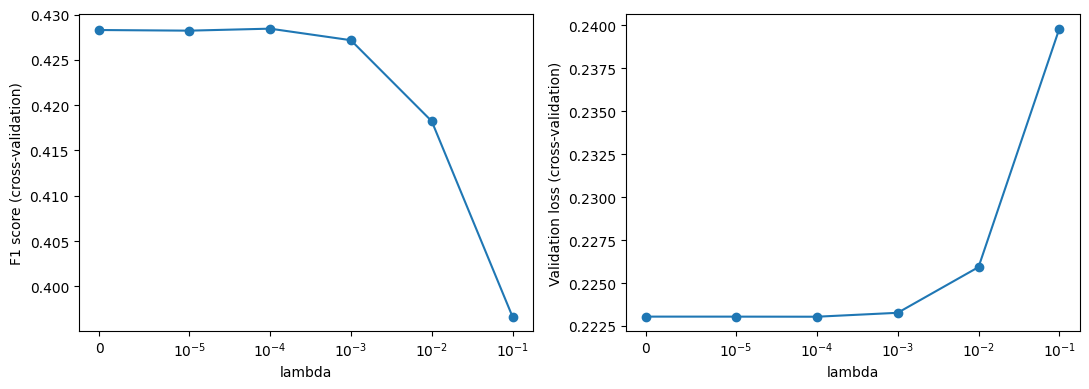

In [142]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(lambdas, [r["f1"] for r in results], marker="o")
axes[0].set_ylabel("F1 score (cross-validation)")

axes[1].plot(lambdas, [r["val_loss"] for r in results], marker="o")
axes[1].set_ylabel("Validation loss (cross-validation)")

for ax in axes:
    ax.set_xscale("symlog", linthresh=1e-5)  # symlog so that lambda = 0 can be shown
    ax.set_xlabel("lambda")

plt.tight_layout()
plt.show()

In [146]:
# predict test labels in {-1, 1}
y_pred = predict_labels(tx_test, w, threshold=0.2)

# sanity checks before writing the file
print("Shapes:", y_pred.shape, test_ids.shape)  # must be equal
print("Values:", np.unique(y_pred, return_counts=True))  # only -1 and 1
print("Share predicted sick:", np.mean(y_pred == 1))  # around 10-15% expected

# write the submission file (columns: Id, Prediction)
create_csv_submission(test_ids, y_pred, "submission.csv")

Shapes: (109379,) (109379,)
Values: (array([-1,  1]), array([94023, 15356]))
Share predicted sick: 0.14039257992850548
